In [2]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT_DIR = Path.cwd().resolve().parents[1]

# Ruta relativa des de 'Projecte_Big_Data/scripts/' cap a 'data/processed/education/'
ruta_csv = ROOT_DIR / "data" / "processed" / "education" / "resultats_academics__quart_eso_processat.csv"

# Llegim el CSV ja separat per columnes (indiquem decimal="," per les comes de les notes)
df = pd.read_csv(ruta_csv, sep=";", decimal=",")

print(f"Files totals carregades: {len(df)}")
display(df.head())

Files totals carregades: 929604


,ANY,PCAT,PCAT_CL,PCAT_EE,PMAT,GENERE
0,2025,83.0,80.0,87.50,91.250000,D
1,2025,72.9,84.0,56.25,57.500000,D
2,2025,77.9,84.0,68.75,83.750000,H
3,2025,87.6,96.0,75.00,79.166667,D
4,2025,87.6,96.0,75.00,78.333333,D


In [3]:
cols_notes = ["PCAT","PCAT_CL","PCAT_EE","PMAT"]
df["GENERE"] = df["GENERE"].astype(str).str.strip().str.upper()
df = df[df["GENERE"].isin(["H","D"])].copy() #mirem que no hi hagi cap fila en buit, saltem les que ho estiguin

df["ANY"] = pd.to_numeric(df["ANY"], errors="coerce")
for col in cols_notes:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(",", "."), errors="coerce") #mirem que no hi hagi strings i tot sigui numeric

df_net = df.dropna(subset=["ANY"]).dropna(subset=cols_notes, how="all").copy() 
df_net["ANY"] = df_net["ANY"].astype(int) #saltem totes les files que no continguin cap nota

print(f"Alumnes vàlids amb almenys una nota: {len(df_net)}") #quants alumnes hi ha amb almenys una nota?

Alumnes vàlids amb almenys una nota: 914591


Aquesta instrucció: df["GENERE"] = df["GENERE"].astype(str).str.strip().str.upper() agafa la columna "GENERE" i li aplica tres transformacions encadenades d'esquerra a dreta abans de sobreescriure-la:

- astype(str): Converteix tots els valors de la columna a text (cadena de caràcters). Això evita errors si hi ha cel·les buides (NaN) o números barrejats.

- str.strip(): Elimina qualsevol espai en blanc sobrant al principi o al final del text (per exemple, converteix " H " en "H").

- str.upper(): Passa totes les lletres a majúscules (per exemple, converteix "h" o "d" en "H" o "D").

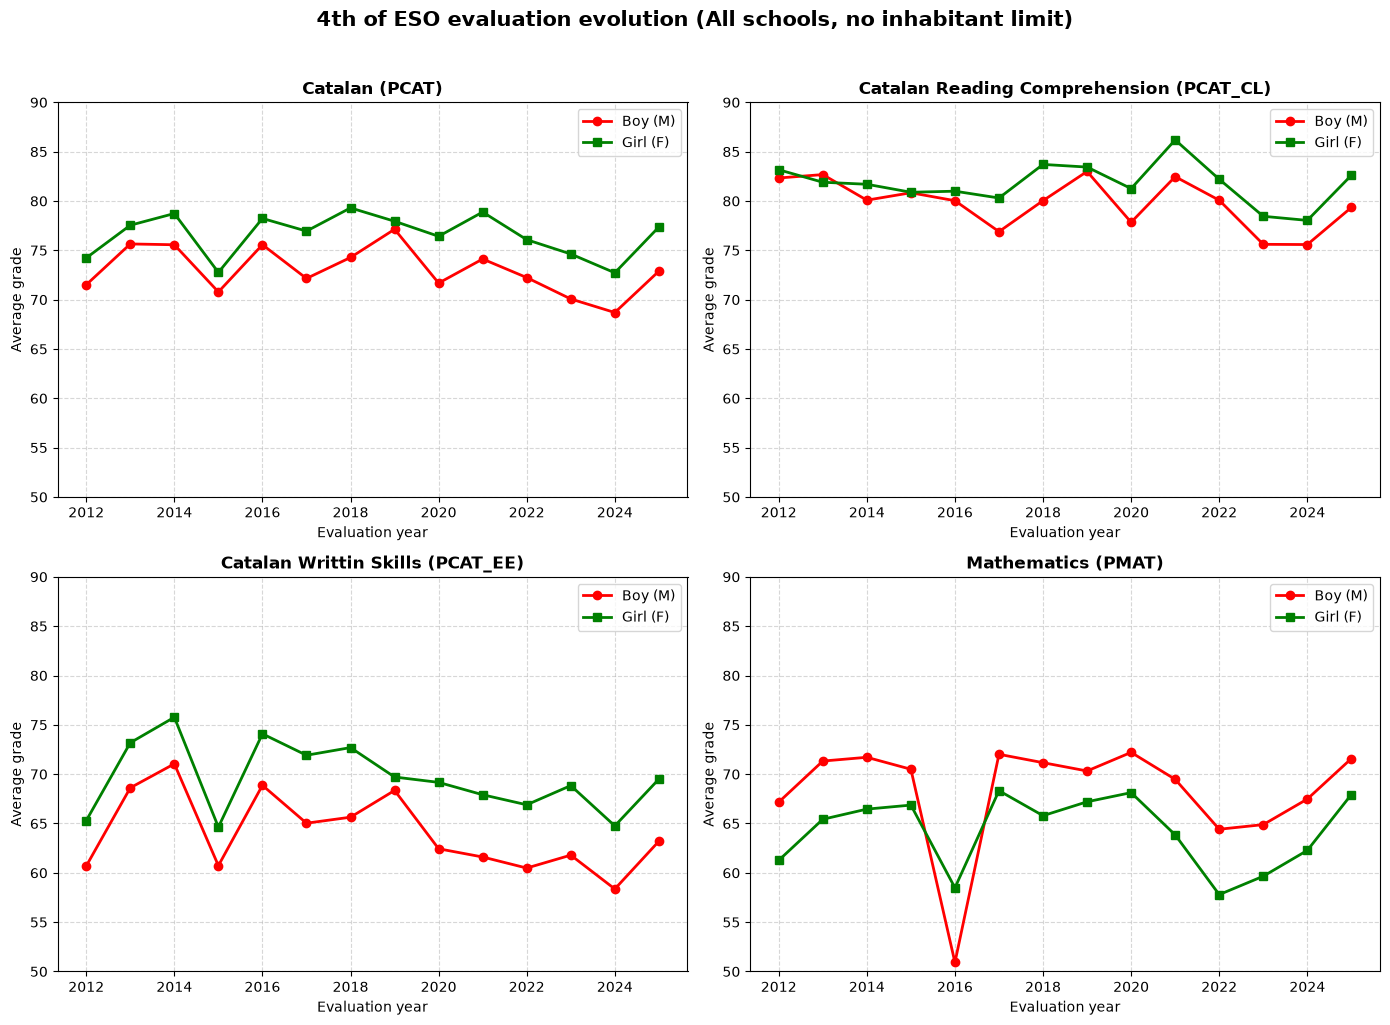

In [8]:
ROOT_DIR = Path.cwd().resolve().parents[1]

#agrupem per any i gènere i calculem la mitjana de cada assignatura
mitjanes = (df_net.groupby(["ANY", "GENERE"])[cols_notes].mean().unstack("GENERE"))
#creem un diccionari per posar els titols als gràfics
assignatures = {"PCAT": "Catalan (PCAT)","PCAT_CL": "Catalan Reading Comprehension (PCAT_CL)",
    "PCAT_EE": "Catalan Writtin Skills (PCAT_EE)","PMAT": "Mathematics (PMAT)"}

# Creem la figura amb 4 gràfics (graella 2x2)
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for idx, (col_nota, titol) in enumerate(assignatures.items()):
    ax = axes[idx]
    
    # Línia dels nois ('H') en vermell
    if "H" in mitjanes[col_nota]:
        ax.plot(
            mitjanes.index,
            mitjanes[col_nota]["H"],
            color="red",
            marker="o",
            linewidth=2,
            label="Boy (M)"
        )
        
    # Línia de les noies ('D') en verd
    if "D" in mitjanes[col_nota]:
        ax.plot(
            mitjanes.index,
            mitjanes[col_nota]["D"],
            color="green",
            marker="s",
            linewidth=2,
            label="Girl (F)"
        )
    
    ax.set_title(titol, fontsize=12, fontweight="bold")
    ax.set_xlabel("Evaluation year", fontsize=10)
    ax.set_ylabel("Average grade", fontsize=10)
    ax.set_ylim([50, 90])
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best")
    
    # Eix X amb anys enters (sense decimals)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.suptitle("4th of ESO evaluation evolution (All schools, no inhabitant limit)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()

# Guarda la figura a la carpeta de resultats del projecte
ruta_figura = ROOT_DIR / "results" / "figures" / "evolucio_4t_eso.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()


,PCAT,PCAT_CL,PCAT_EE,PMAT
ANY,,,,
2012,72.862579,82.746542,62.978613,64.232209
2013,76.592570,82.291691,70.893391,68.389926
2014,77.139191,80.885781,73.392494,69.100770
2015,71.781267,80.861581,62.697985,68.664002
2016,76.914107,80.517835,71.504319,54.731013
2017,74.566774,78.613385,68.499340,70.155256
2018,76.816649,81.892505,69.205364,68.452090
2019,77.535050,83.212555,69.021284,68.755836
2020,74.050190,79.550530,65.802186,70.169244


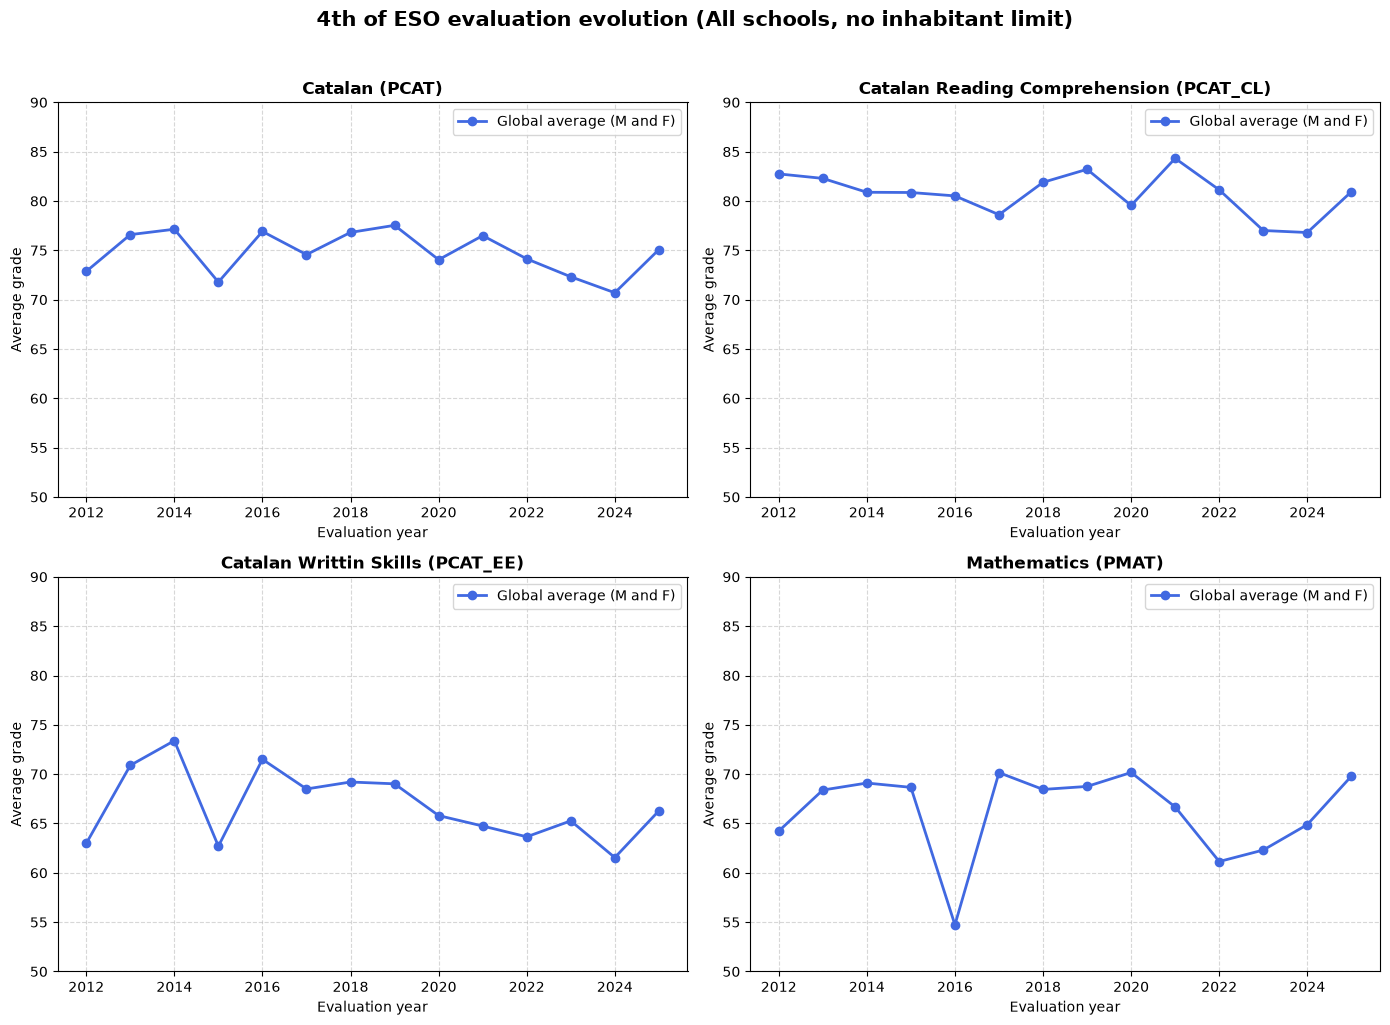

In [7]:
# Agrupem només per ANY per obtenir el promig global entre nois i noies
mitjanes = (
    df_net
    .groupby("ANY")[cols_notes]
    .mean()
    .sort_index()
)

display(mitjanes)

assignatures = {"PCAT": "Catalan (PCAT)","PCAT_CL": "Catalan Reading Comprehension (PCAT_CL)",
    "PCAT_EE": "Catalan Writtin Skills (PCAT_EE)","PMAT": "Mathematics (PMAT)"}

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(14, 10))
axes = axes.flatten()

for idx, (col_nota, titol) in enumerate(assignatures.items()):
    ax = axes[idx]
    
    ax.plot(
        mitjanes.index,
        mitjanes[col_nota],
        color="royalblue",
        marker="o",
        linewidth=2,
        label="Global average (M and F)"
    )
    
    ax.set_title(titol, fontsize=12, fontweight="bold")
    ax.set_xlabel("Evaluation year", fontsize=10)
    ax.set_ylabel("Average grade", fontsize=10)
    ax.set_ylim([50, 90])
    ax.grid(True, linestyle="--", alpha=0.5)
    ax.legend(loc="best")
    
    # Forcem que l'eix X mostri anys enters (sense decimals)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))

plt.suptitle("4th of ESO evaluation evolution (All schools, no inhabitant limit)", fontsize=15, fontweight="bold", y=1.02)
plt.tight_layout()

# Desem la figura fent servir ROOT_DIR
ruta_figura = ROOT_DIR / "results" / "figures" / "evolucio_4t_eso_global.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()